In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath(''))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np

from utils.plots import *
plt.rcParams.update({'axes.xmargin': 0.05})
import seaborn as sns

data_dir = Path('../../data/aurora/')
df_dir = Path('../dfs')
df_dir.mkdir(exist_ok=True, parents=True)

In [3]:
df_all = pd.read_csv(df_dir / 'df_all.csv')


In [4]:
def plot_demographics(df):
    df_drop = df.drop_duplicates(subset='pid')
    plt.figure(figsize=(12,4))
    plt.subplot(2,4,1)
    sns.countplot(df_drop, x='gender')
    plt.subplot(2,4,2)
    sns.countplot(df_drop, x='fitzpatrick_scale')
    plt.subplot(2,4,3)
    sns.histplot(df_drop, x='age')
    plt.subplot(2,4,5)
    sns.histplot(df_drop, x='weight')
    plt.subplot(2,4,6)
    sns.histplot(df_drop, x='height')
    plt.subplot(2,4,7)
    sns.histplot(df_drop, x='bmi')
    plt.subplot(2,4,4)
    sns.histplot(df, x='pressure_quality', bins=np.linspace(0, 1, 11))
    plt.subplot(2,4,8)
    sns.histplot(df, x='optical_quality', bins=np.linspace(0, 1, 11))
    plt.show()


Aurora dataset:
38,623 recordings from 1220 people


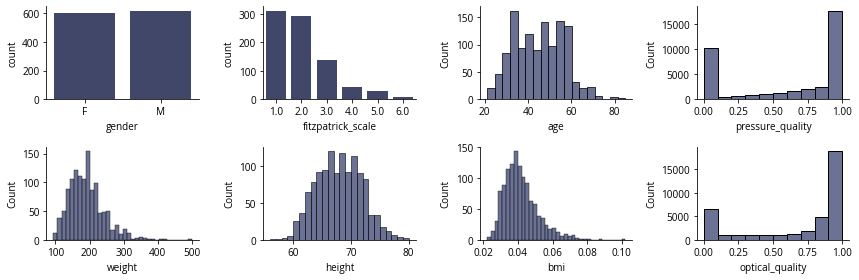

In [5]:
print('Aurora dataset:')
print(f'{len(df_all):,} recordings from {df_all.pid.nunique()} people')
plot_demographics(df_all)


Valid ECG:
29,526 recordings from 1196 people


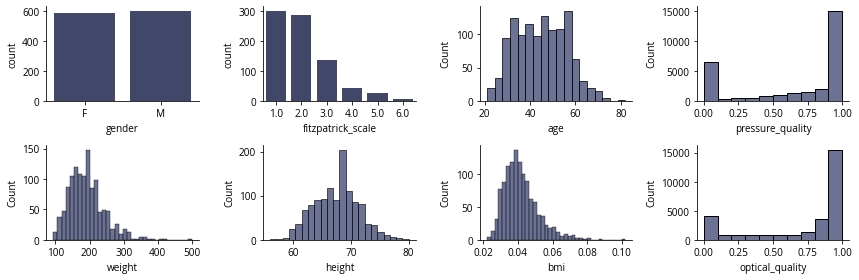

In [6]:
df_all = df_all[df_all.valid_ecg]
print('Valid ECG:')
print(f'{len(df_all):,} recordings from {df_all.pid.nunique()} people')
plot_demographics(df_all)


Subset for training h:
978 recordings from 253 people


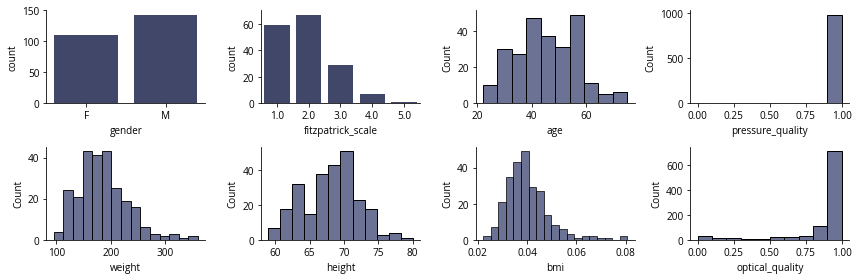

In [7]:
df_all['is_train_h'] = (df_all.pressure_quality >= 1.0) & (df_all.hr_ekg <= 55)
df_train_h = df_all[df_all.is_train_h]

print('Subset for training h:')
print(f'{len(df_train_h):,} recordings from {df_train_h.pid.nunique()} people')
plot_demographics(df_train_h)


Subset for training z:
7,019 recordings from 253 people


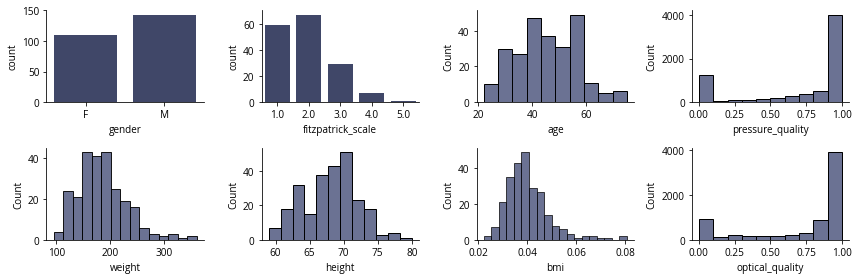

In [8]:
df_all['is_train_z'] = df_all.pid.isin(df_train_h.pid.unique())
df_train_z = df_all[df_all.is_train_z]

print('Subset for training z:')
print(f'{len(df_train_z):,} recordings from {df_train_z.pid.nunique()} people')
plot_demographics(df_train_z)


TEST: 3,342 recordings from 400 people


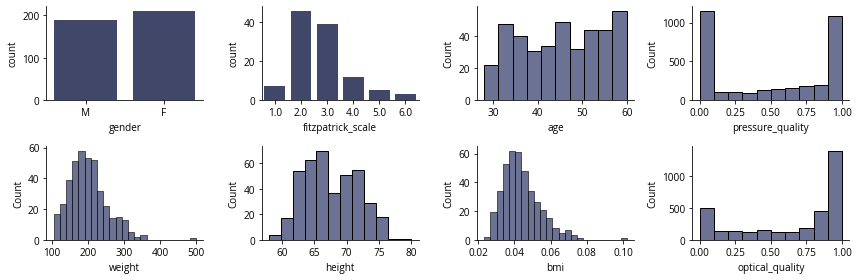

In [9]:
df_all['is_test'] = ~df_all.is_train_h & ~df_all.is_train_z
df_test = df_all[df_all.is_test]

df_test = df_test[df_test.pid.str.startswith('o')]

df_test['posture'] = pd.NA
df_test.loc[df_test.measurement.str.startswith('Supine'),'posture'] = 'supine'
df_test.loc[df_test.measurement.str.startswith('Sitting'),'posture'] = 'seated'
df_test.loc[df_test.measurement.str.startswith('Standing'),'posture'] = 'standing'
df_test.loc[df_test.measurement.str.startswith('Running'),'posture'] = 'running'
df_test.loc[df_test.measurement.str.startswith('Walking'),'posture'] = 'walking'
df_test.dropna(subset='posture', inplace=True)

print(f'TEST: {len(df_test):,} recordings from {df_test.pid.nunique()} people')
plot_demographics(df_test)


TEST PPG: 105 recordings from 21 people


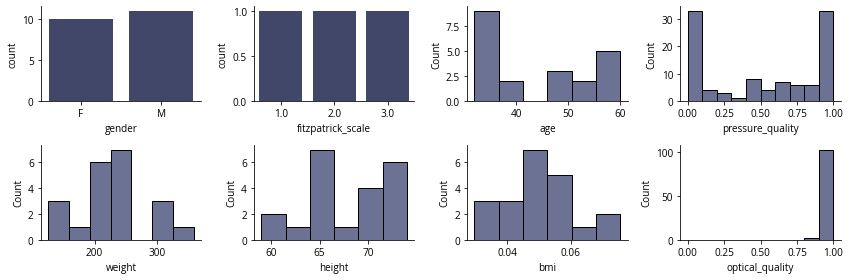

In [10]:
df = df_test.copy()

# signal quality threshold
df = df[df.optical_quality >= 0.89]

# include only participants with (all) these postures
postures = ['supine', 'seated', 'standing', 'walking', 'running']
df = df[df.posture.isin(postures)]
include = set(df.pid)
for p in postures:
    include &= set(df.query(f'posture=="{p}"').pid)
df = df[df.pid.isin(include)]

# take best quality recordings available
df = df.sort_values(by=['optical_quality', 'pressure_quality'], ascending=False)
df = df.drop_duplicates(['pid', 'posture'], keep='first')
df = df.sort_values(by=['pid', 'posture'])

df_test_ppg = df
print(f'TEST PPG: {len(df_test_ppg):,} recordings from {df_test_ppg.pid.nunique()} people')
plot_demographics(df_test_ppg)


In [11]:
df_train_h.to_csv(df_dir/'aurora_train_h_df.csv', index=False)
df_train_z.to_csv(df_dir/'aurora_train_z_df.csv', index=False)
df_test_ppg.to_csv(df_dir/'aurora_test_ppg_df.csv', index=False)
